## 0. 준비

### AWS 계정 생성.

### AWS 프리 티어 사용.
https://aws.amazon.com/ko/free/

무료 플랜 기준으로 6개월 AWS 사용 가능.  
물론 기본 100USD, 최대 200USD 사용 가능.

### 생성 시 화면.

에이전트 툴킷  
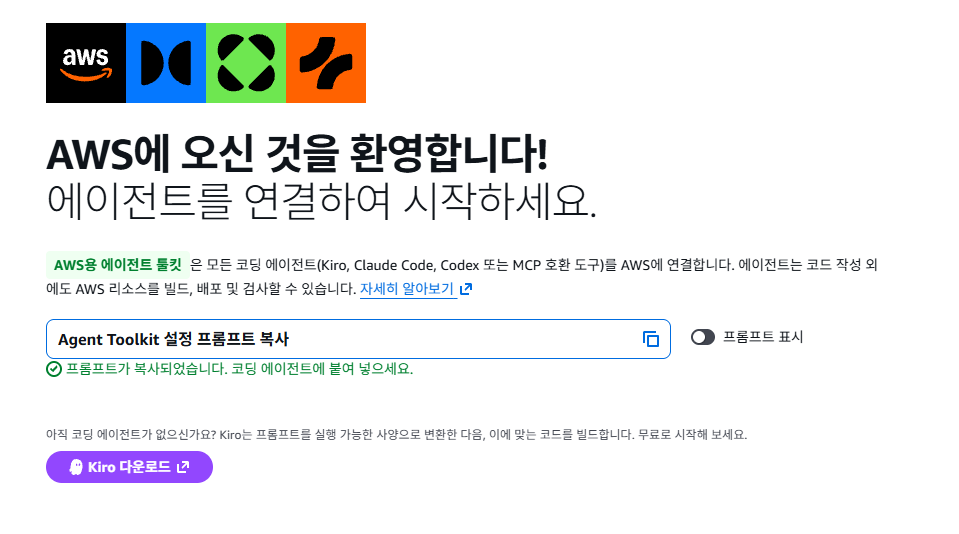  
다음 지침에 따라 AWS용 에이전트 툴킷을 설정합니다.  
https://raw.githubusercontent.com/aws/agent-toolkit-for-aws/refs/heads/main/setup-instructions/setup.md

사용 중인 AWS 리전: ap-southeast-2  
AWS Experience: 새로운 AWS 경험  

위 텍스트를 ai 코딩 에이전트에게 넣기면 ai에게 설정을 넘기는 것.    
지금은 공부를 위함으로 사용하지 않음. 

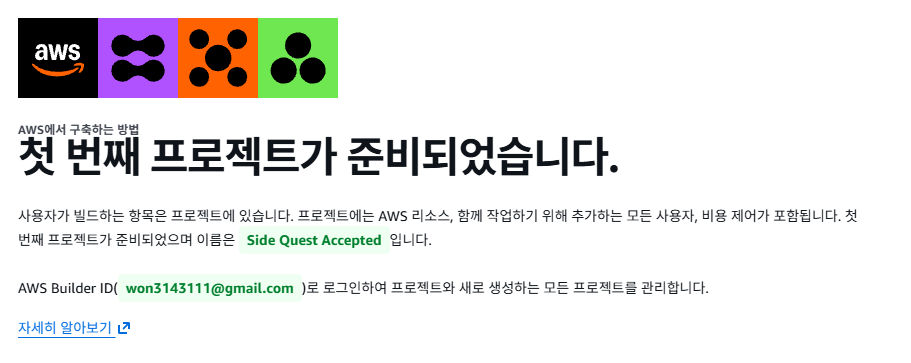

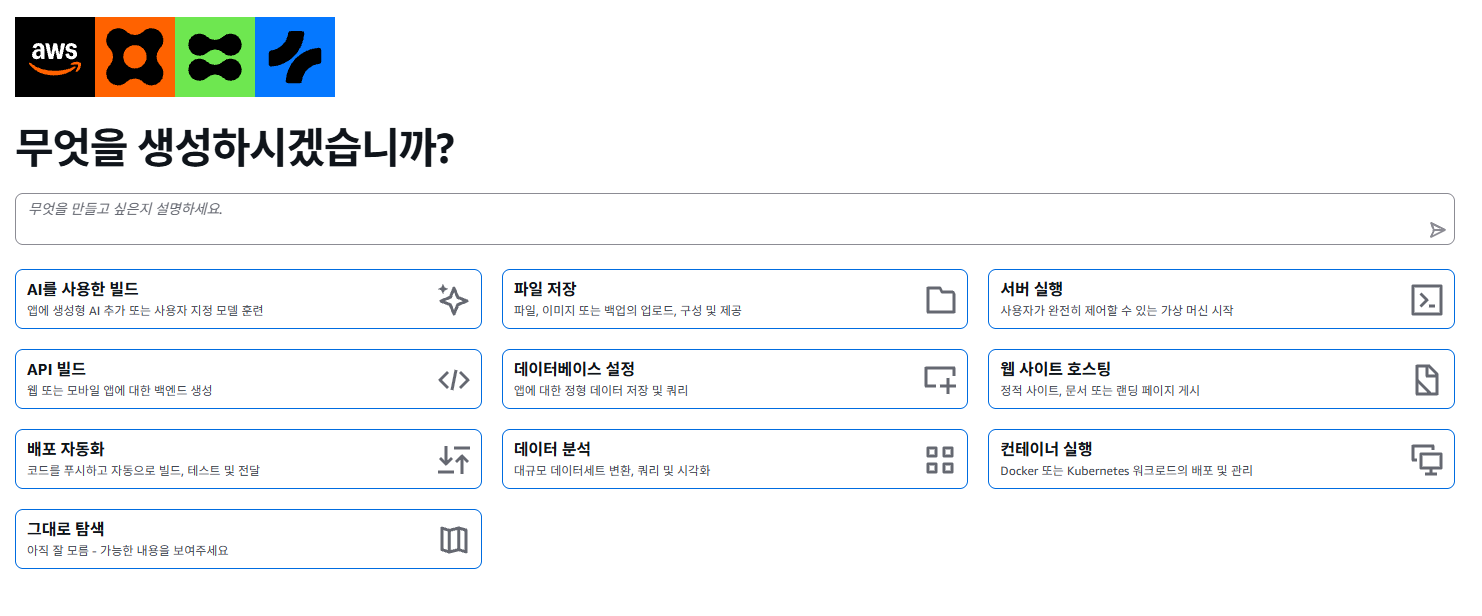  
LLM에게 위임하지 않을 것이므로 서버 생성 시작.


### 서버 생성
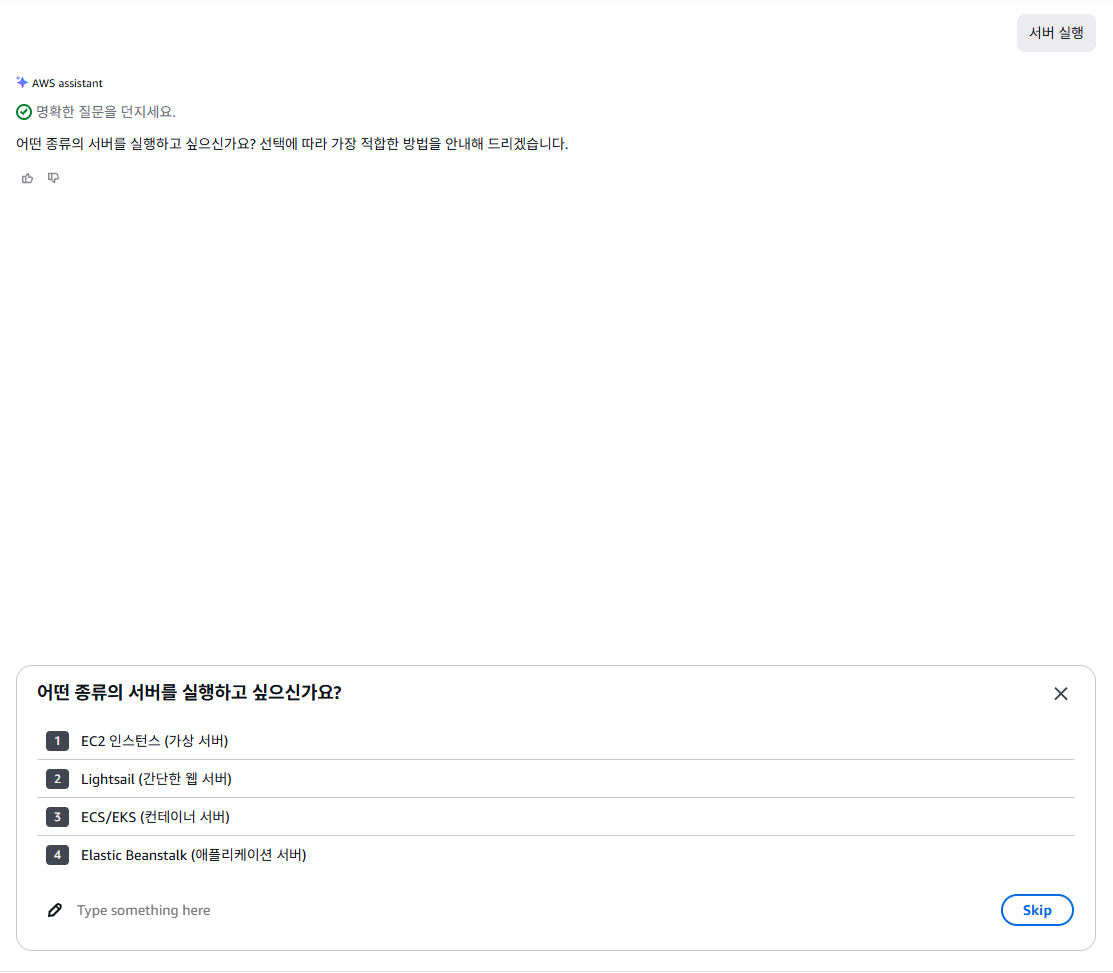

1. EC2 인스턴스 선택.

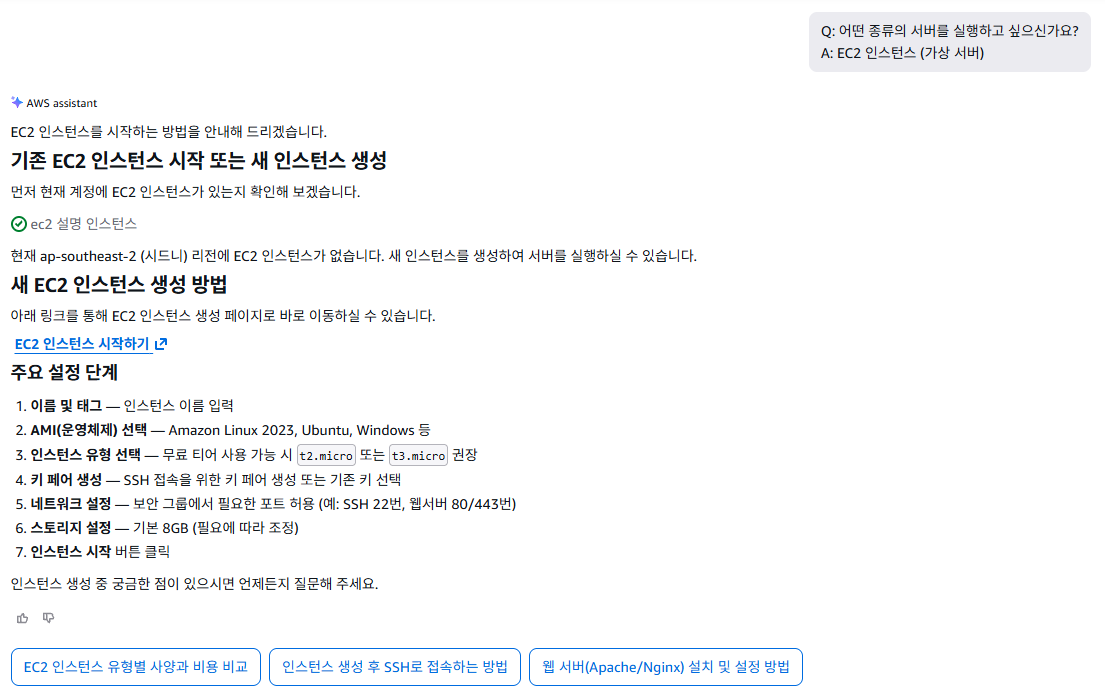

이미지의 EC2 인스턴스 시작하기 버튼을 통해 넘어감.

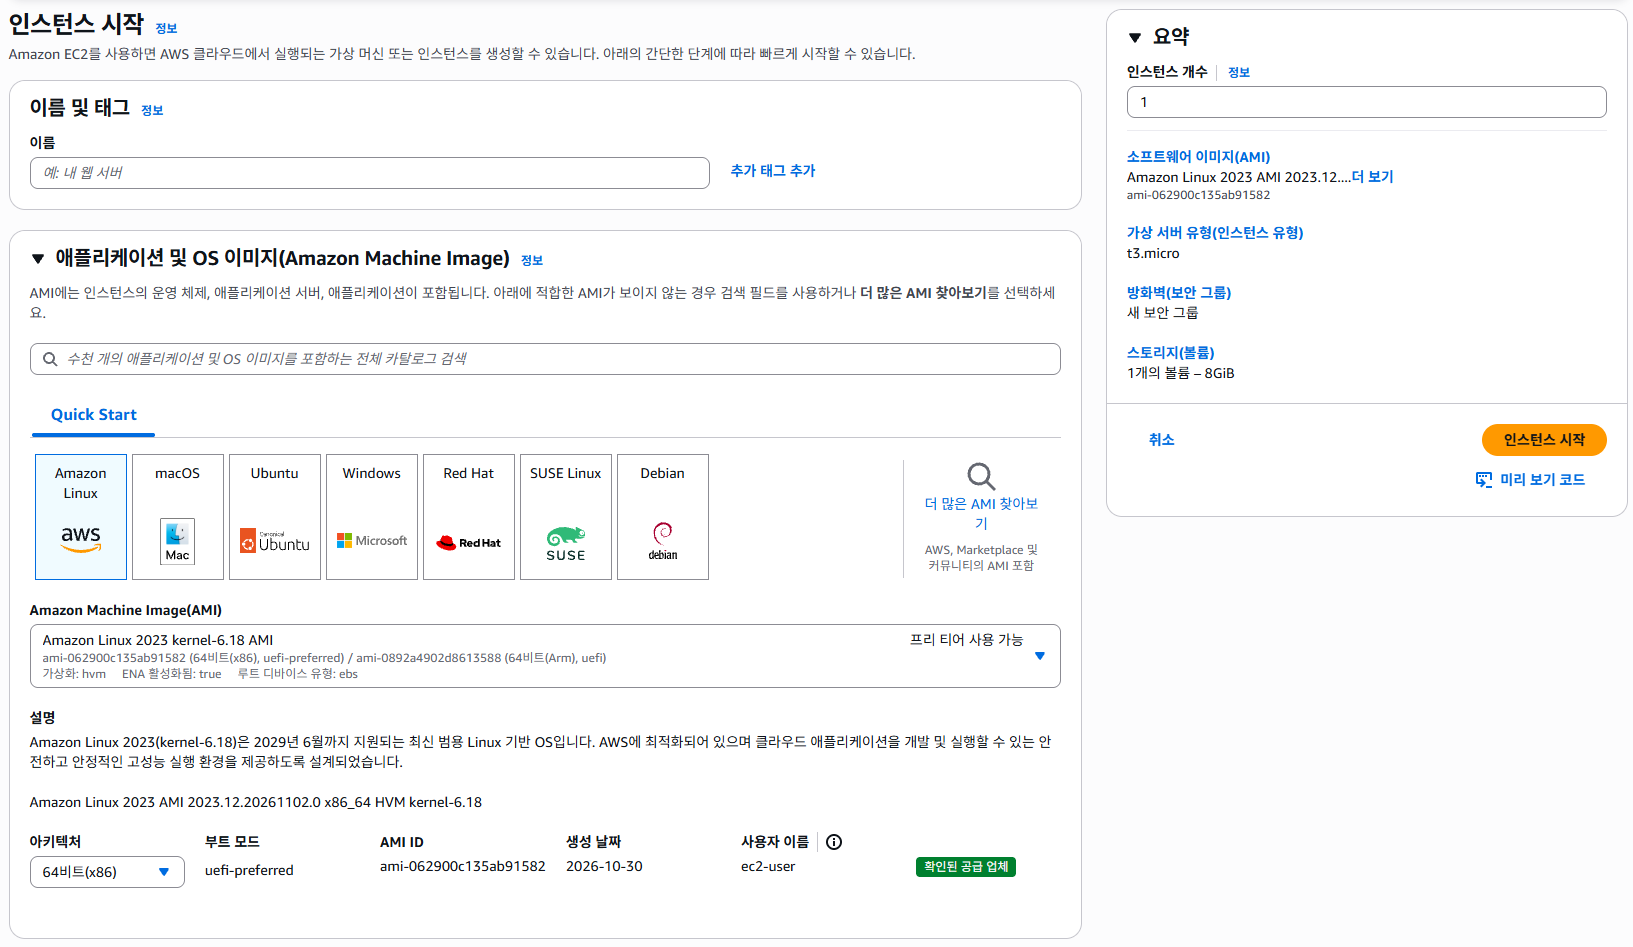

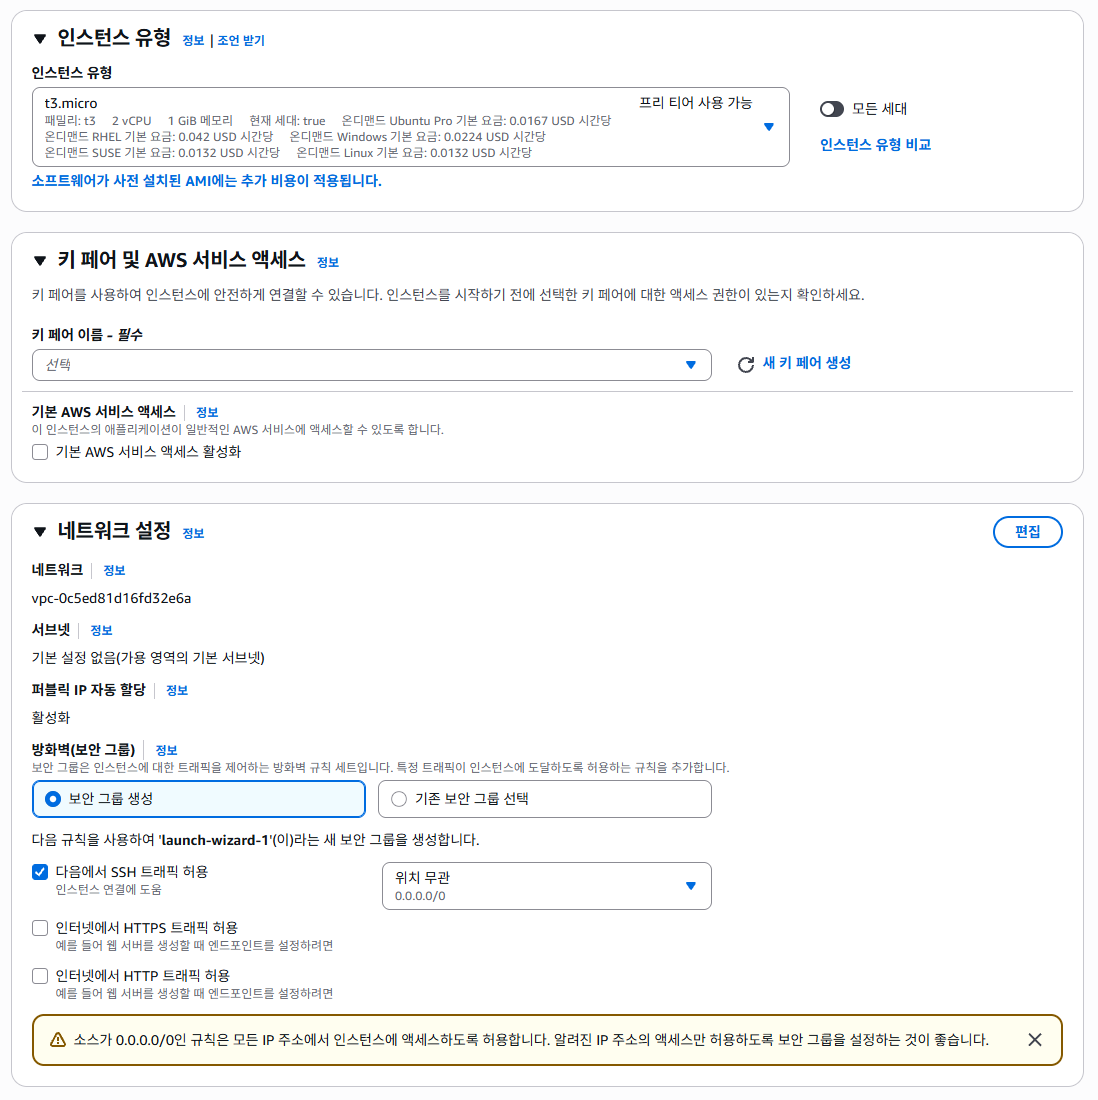

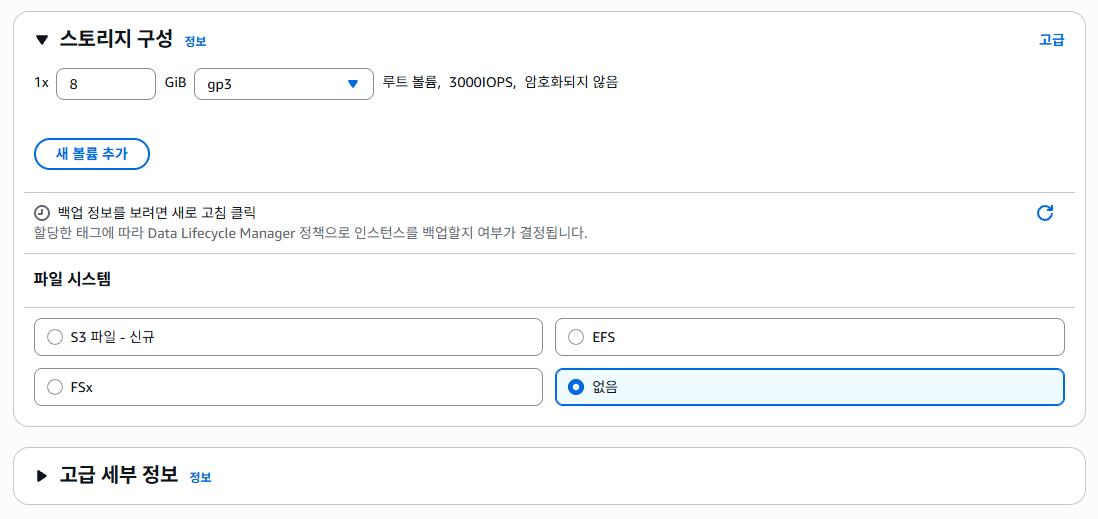

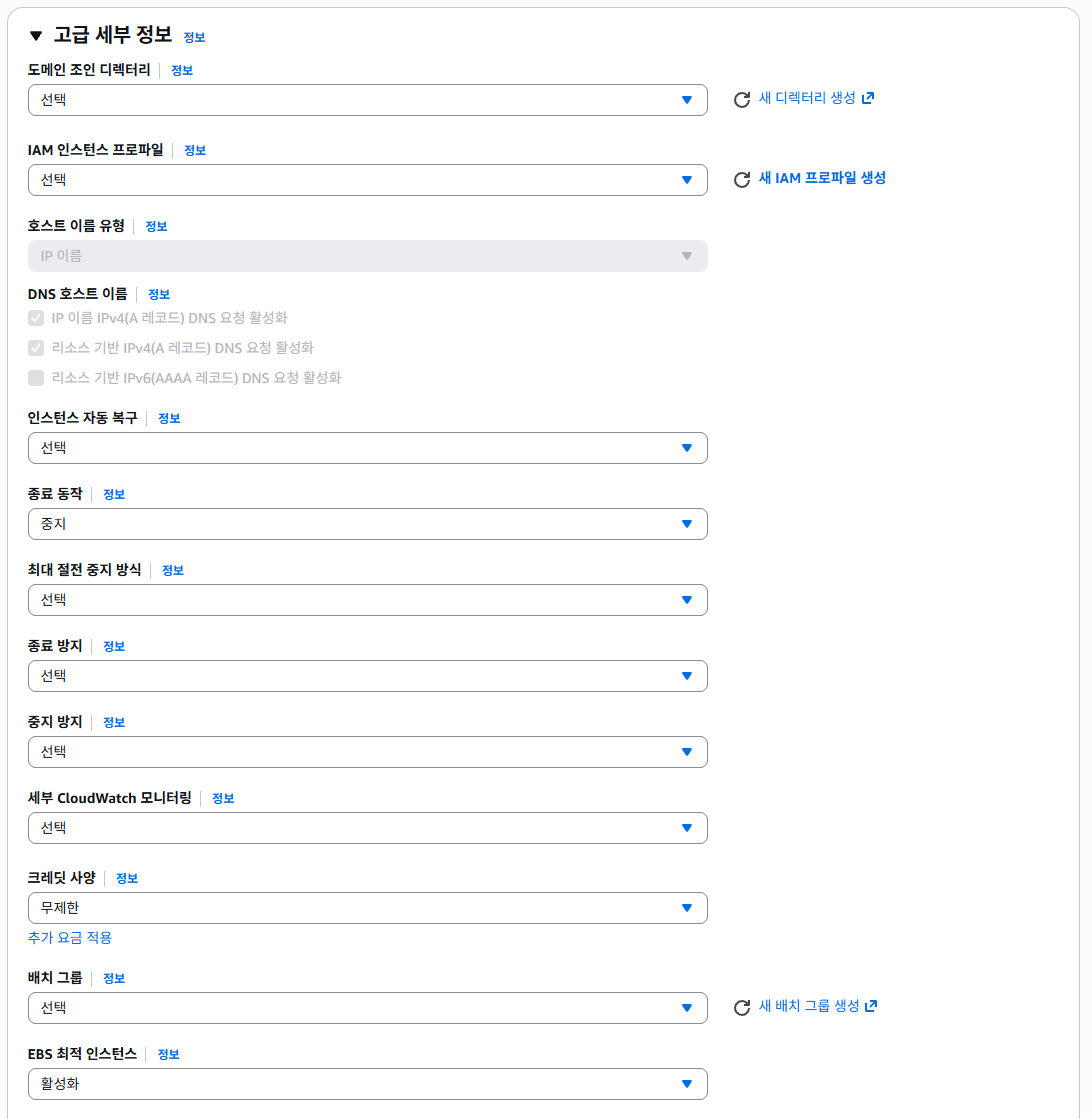

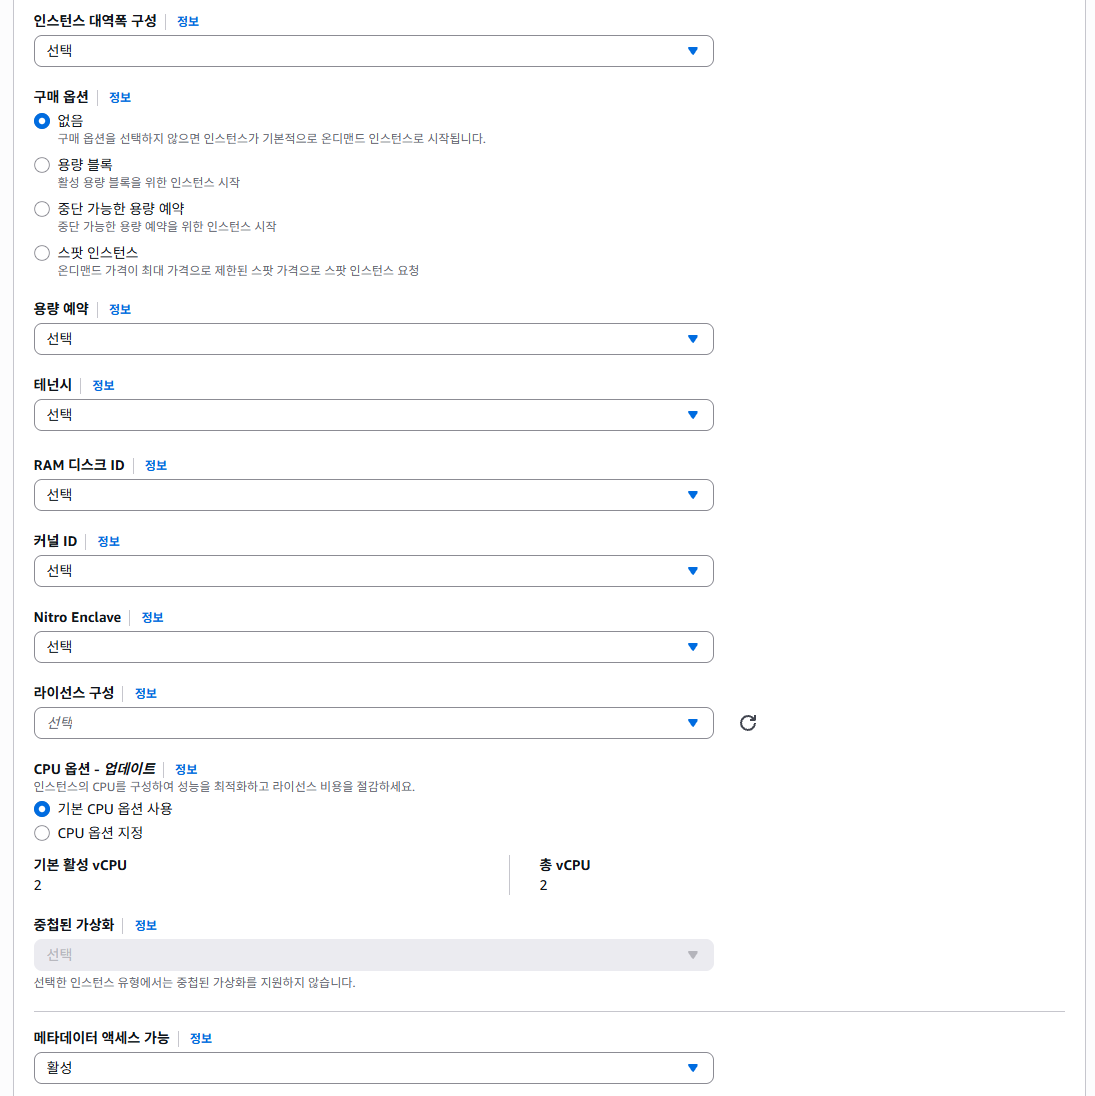

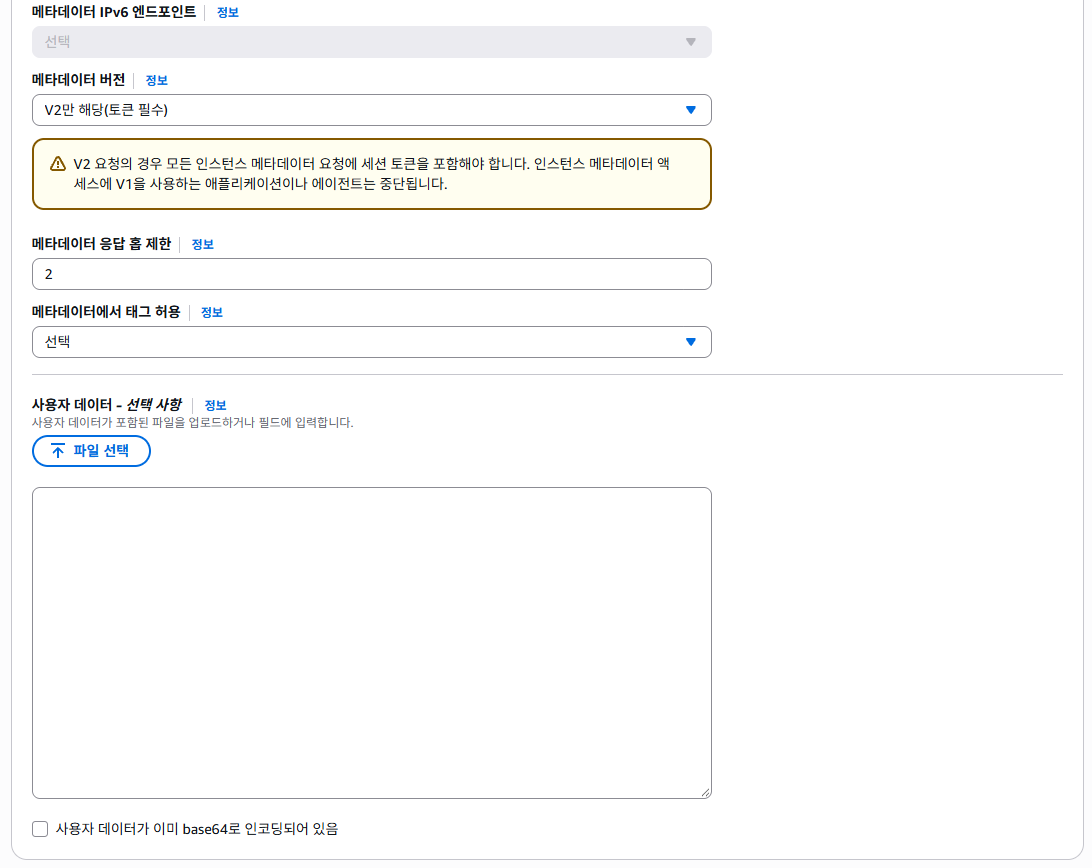

대부분의 설정은 프리 티어 사용 가능한 것을 따르고, 키 페어를 생성.

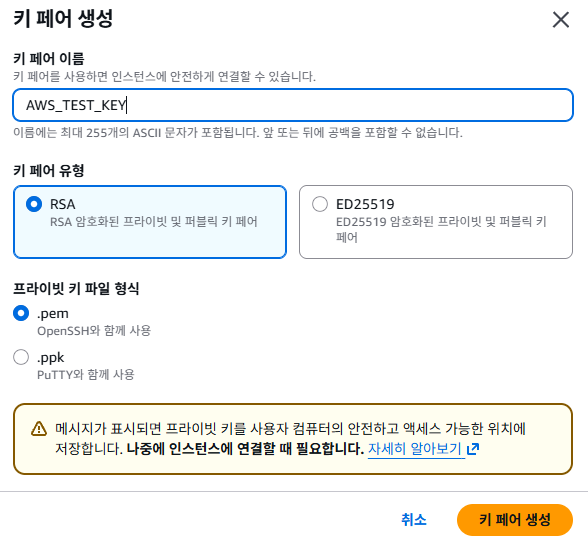

네트워크 설정에 대해서도 SSH는 나만 접근 가능하고, 내가 배포하는 서비스는 누구나 볼 수 있도록 설정.  
SSH는 내 IP로 설정하고, HTTP는 누구나 볼 수 있도록 위치 무관으로 설정. (HTTPS는 추후 인증서 설정 추가 예정)

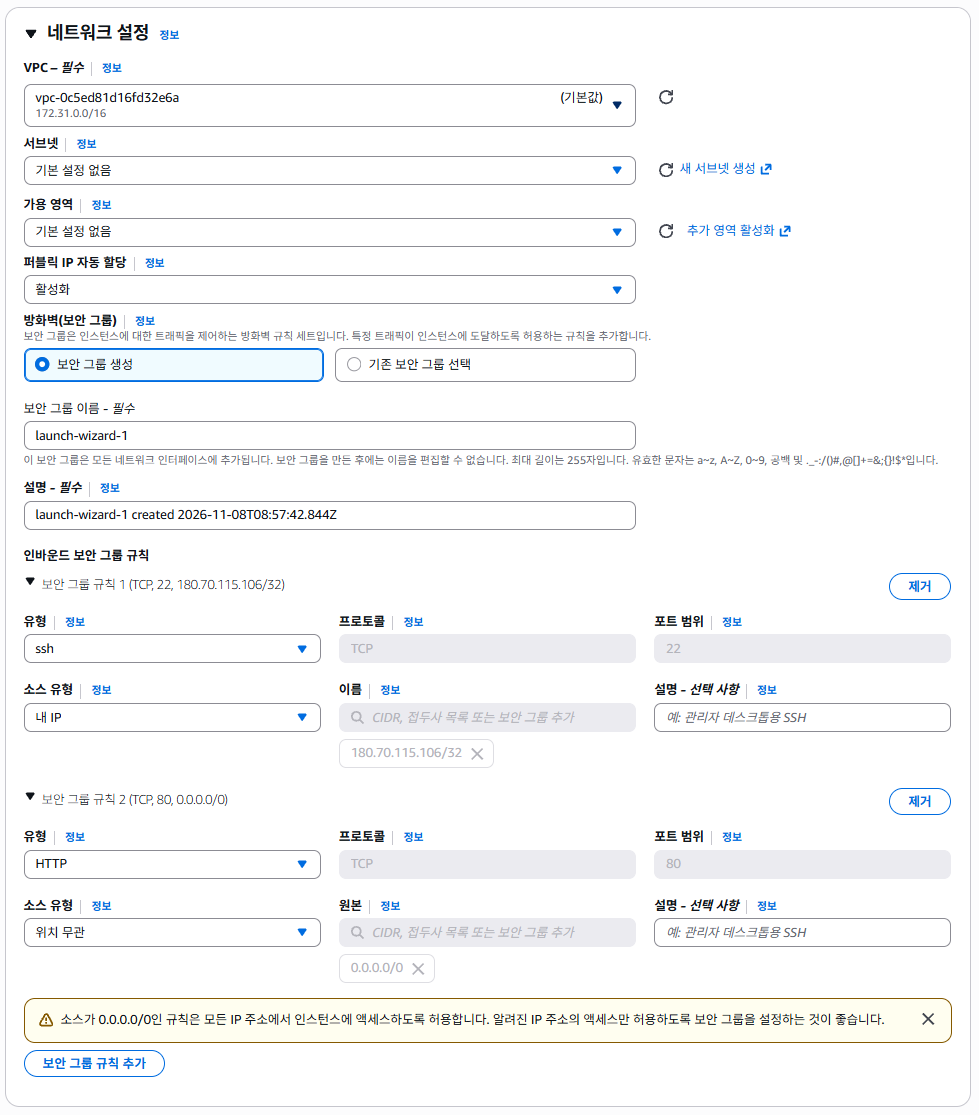

고급 설정은 두고, 인스턴스 시작!

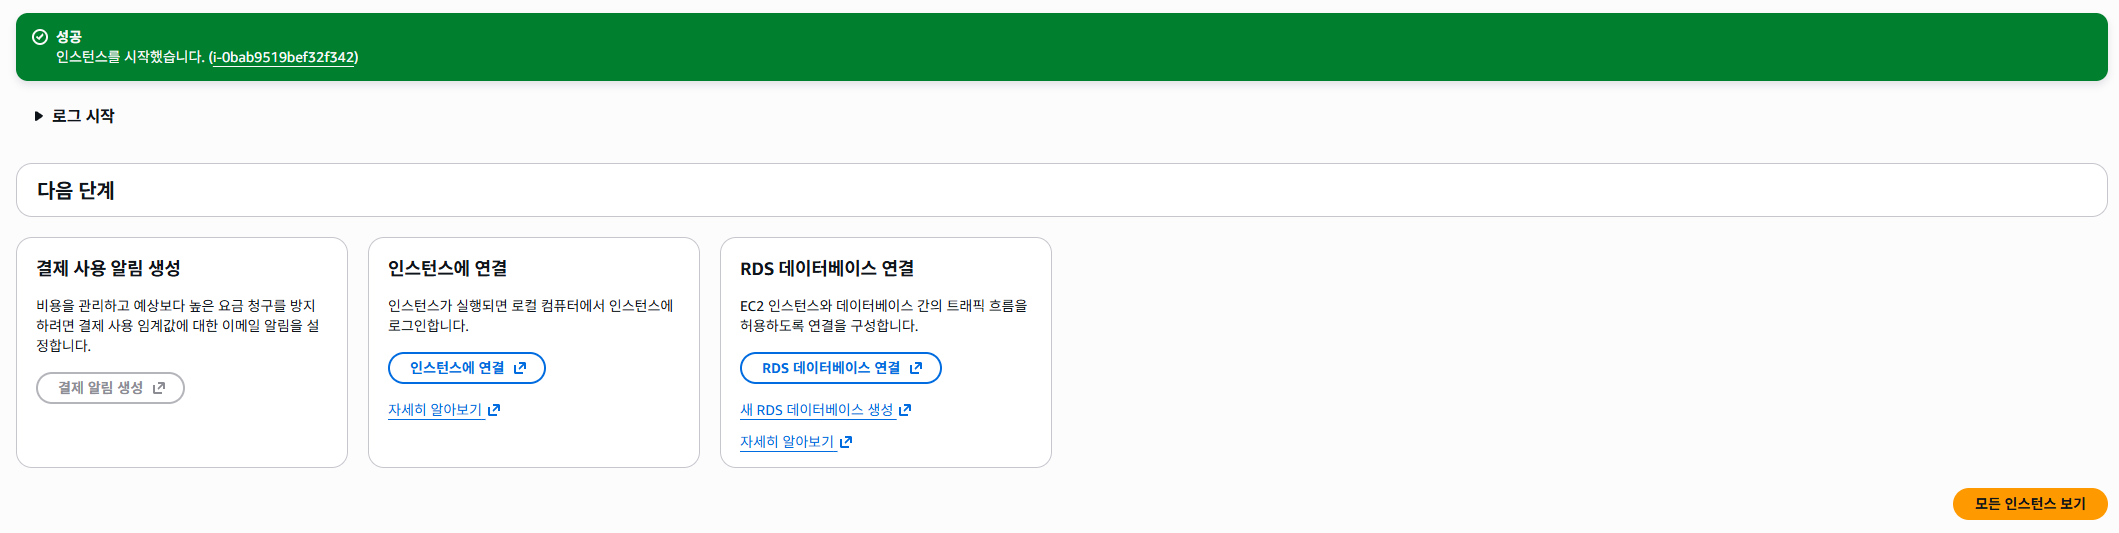

모든 인스턴스 보기

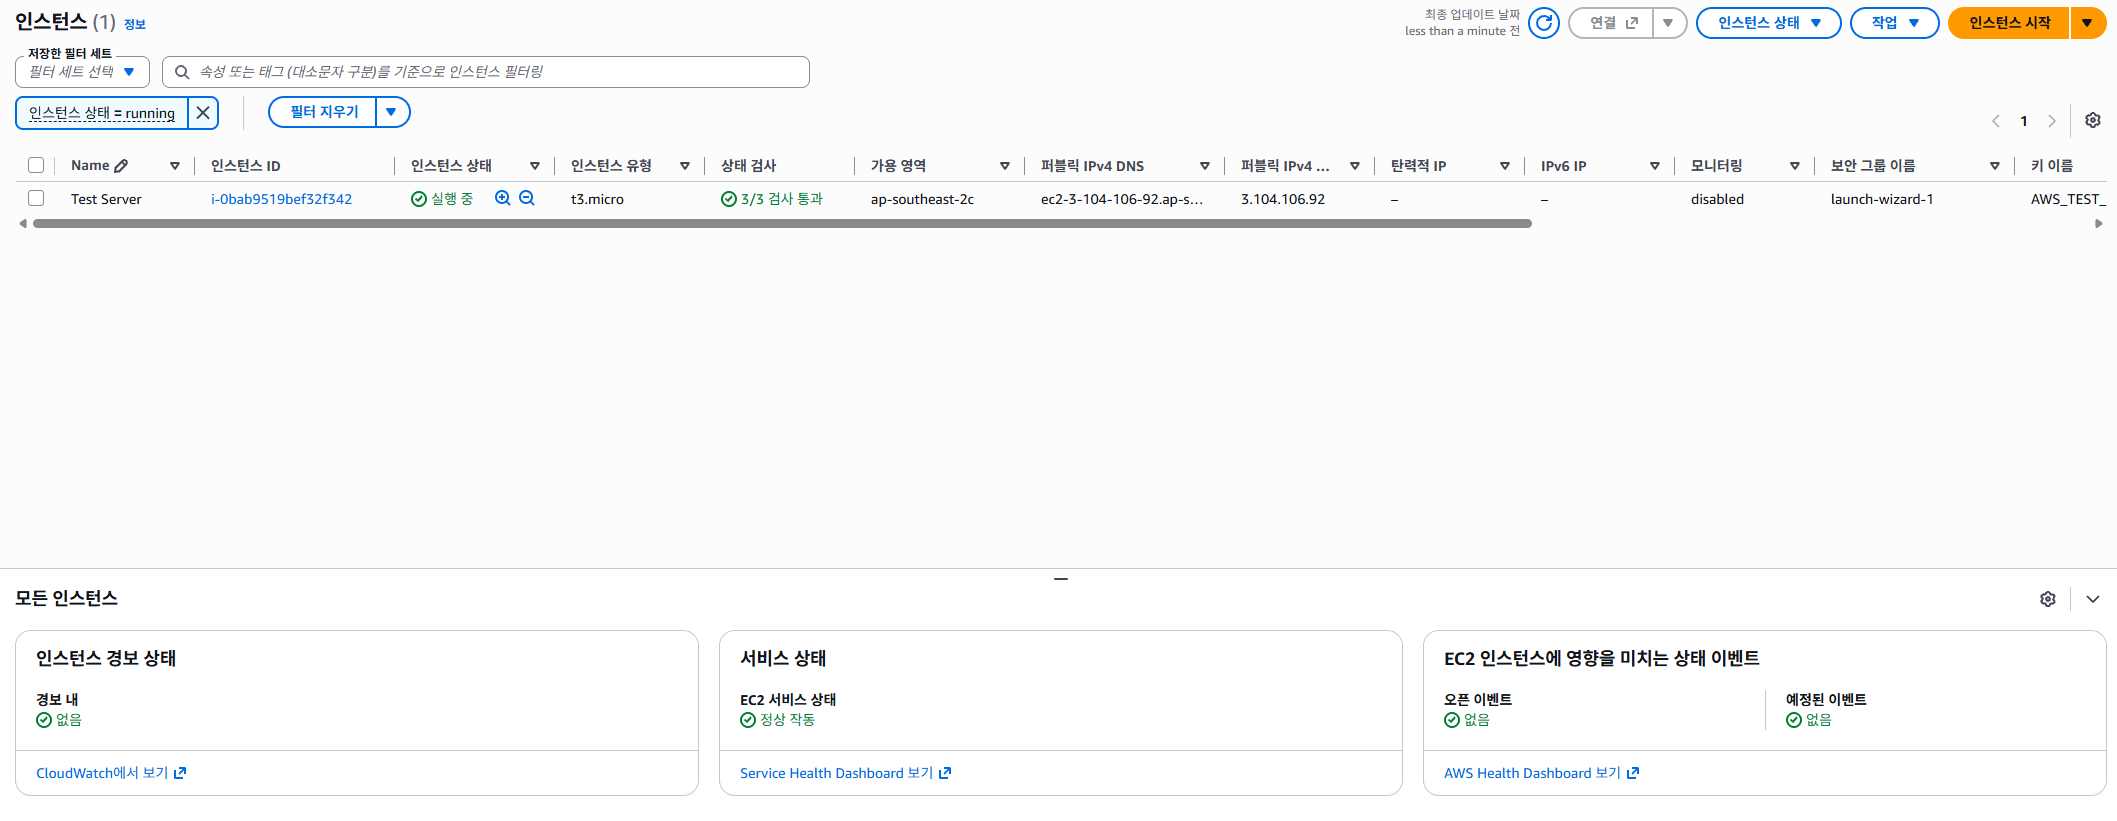

예산과 관련하여 버튼이 눌리지 않지만, 좌측의 채팅창(AWS assistant)를 통해 접근 가능했음.

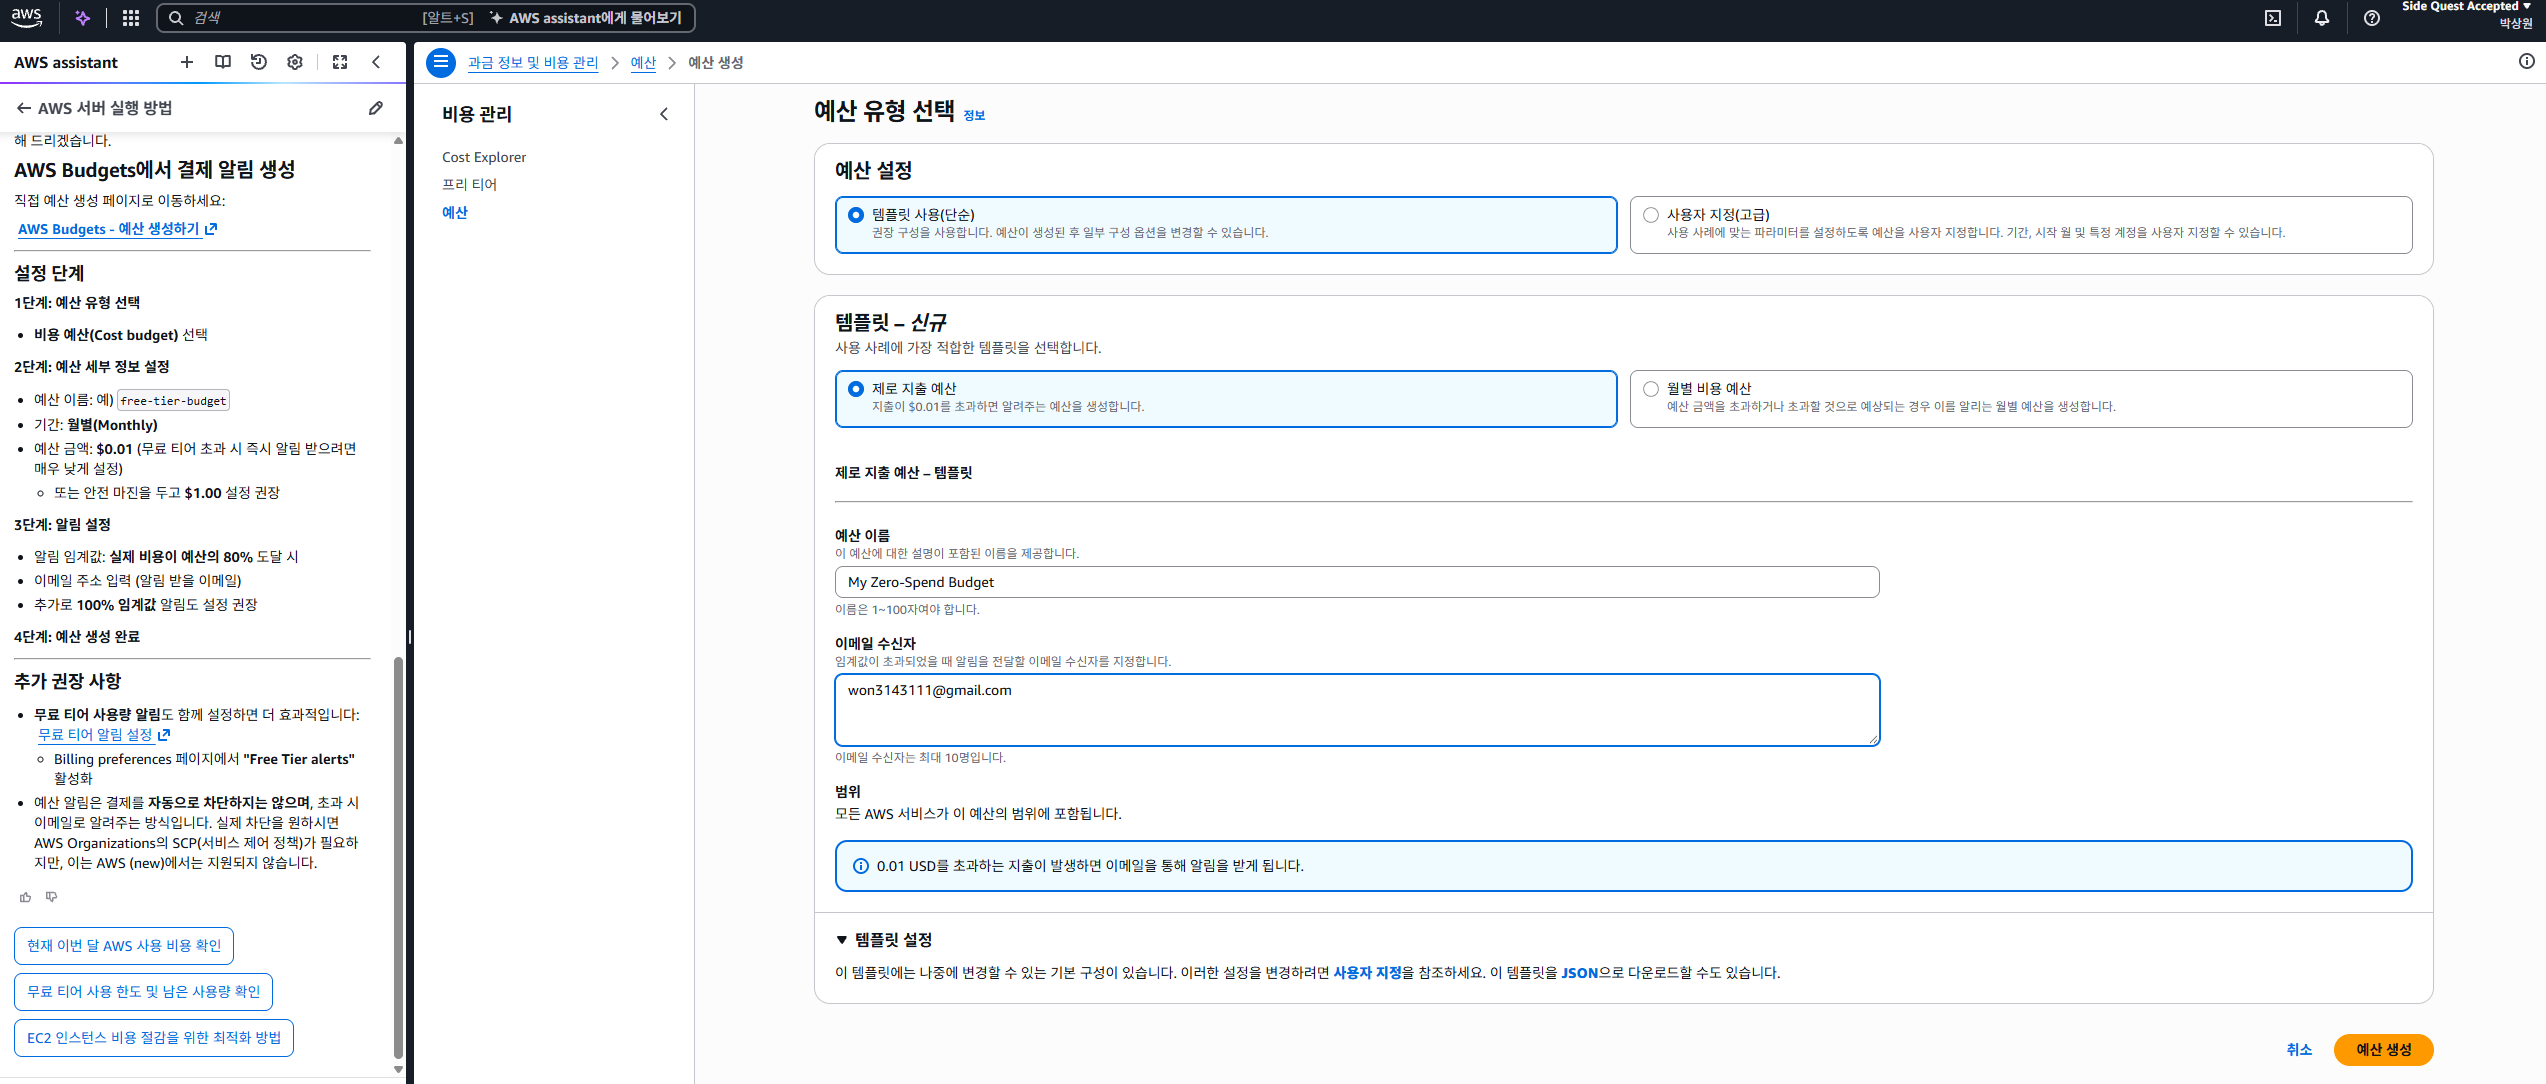

0지출로 설정.

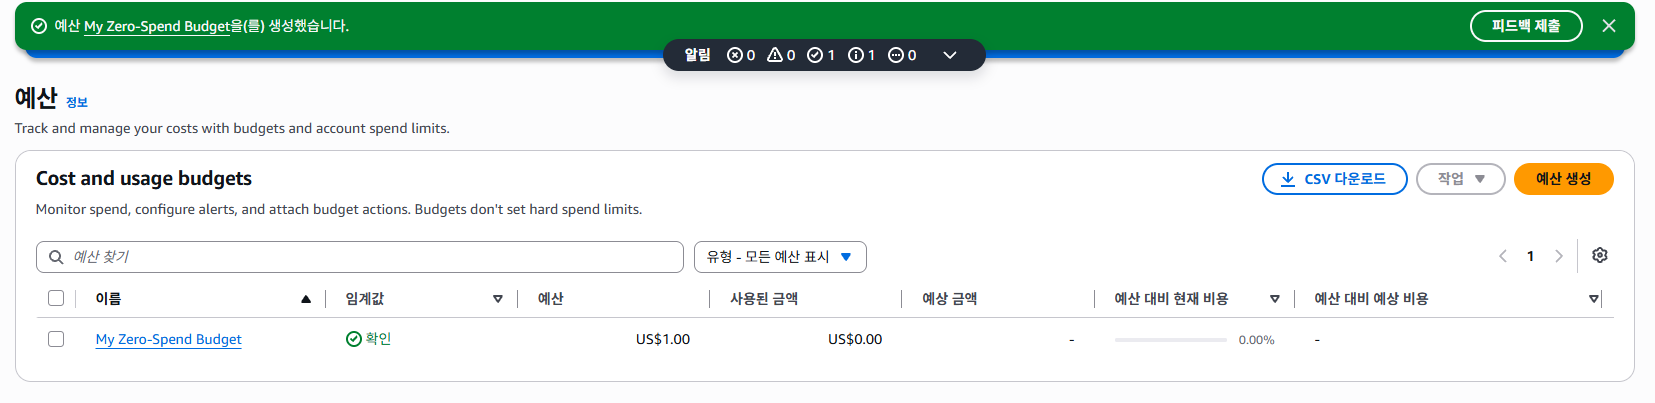

이미 인스턴스가 실행 중이었으므로, SHH 접근 시도.


### 생성한 인스턴스 SHH 접근하기.

터미널에서 .pem이 존재하는 폴더에서 SSH 접근을 위한 명령어 실행.

```bash
icacls "AWS_TEST_KEY.pem" /inheritance:r
icacls "AWS_TEST_KEY.pem" /grant:r "%username%:R"
ssh -i "AWS_TEST_KEY.pem" ec2-user@3.104.106.92
```

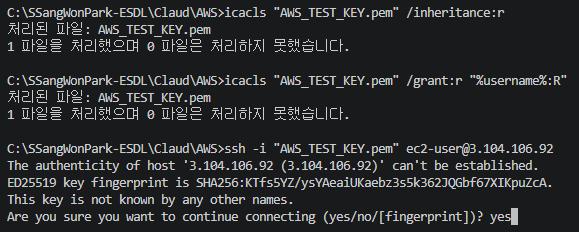

성공!!

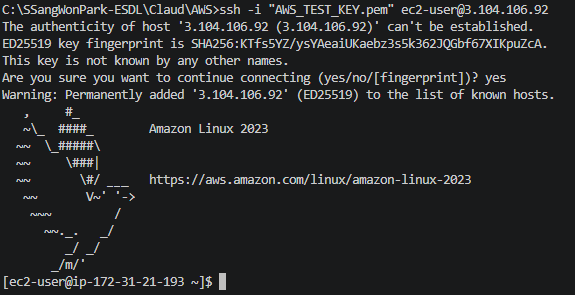


### 서버를 통해 페이지 올려보기.
SSH 연결을 통해 Nginx 설치 후 페이지 올려보기.

패키지 업데이트
```bash
sudo dnf update -y
```

Nginx 설치
```bash
sudo dnf install nginx -y
```

Nginx 실행 및 부팅 시 자동 시작 설정
```bash
sudo systemctl enable --now nginx
```

확인하기
```bash
sudo systemctl status nginx
```

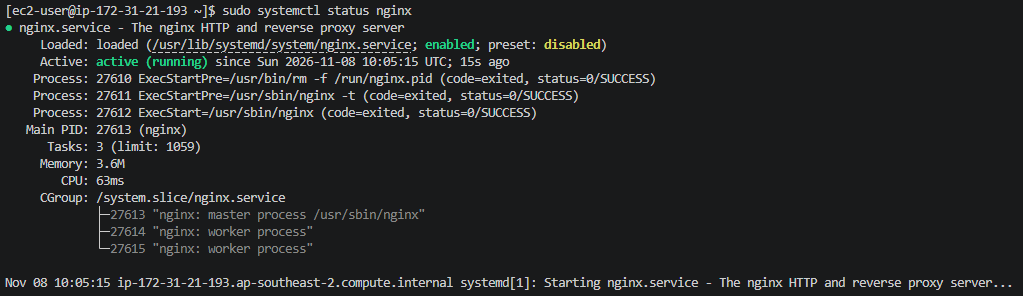

현재 running으로 정상적으로 실행 중. (이미지의 초록색 부분)

테스트용으로 페이지 올리기. html 한줄로 이루어진 페이지.
```bash
echo "<html><body><h1>Hello from my first EC2 server! - SangWon</h1></body></html>" | sudo tee /usr/share/nginx/html/index.html
```

http://3.104.106.92 에서 확인 가능!

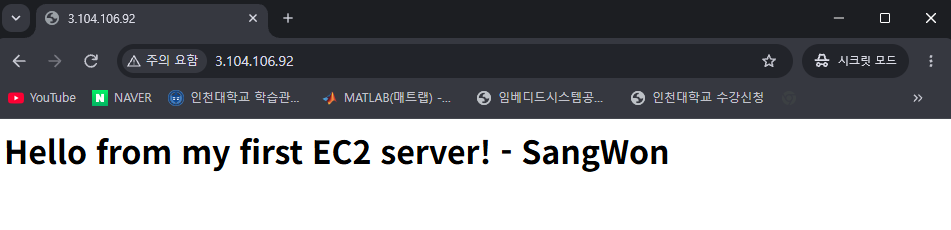